# Tutorial 8: Simulation Domains with DomainMesh

**What You Will Build:** one `DomainMesh` that holds the flow past a
cylinder, its wall, its far field, and the freestream velocity. One call then
checks, rotates, or saves all of them.

A simulation sample is more than one mesh. This tutorial covers the following
tasks:

- Build a `DomainMesh` from a computational fluid dynamics (CFD) result, and
  inspect its parts
- Check, draw, and rotate a whole domain, with its vector fields
- Combine the meshes of a domain in spatial queries, and save the domain

Needs [Tutorial 2](tutorial_2_io_interop.ipynb),
[Tutorial 4](tutorial_4_operations.ipynb), and
[Tutorial 7](tutorial_7_quality_repair.ipynb). Runs on a CPU. The first run
downloads a small dataset (under 1 MB) from the PyVista examples repository.

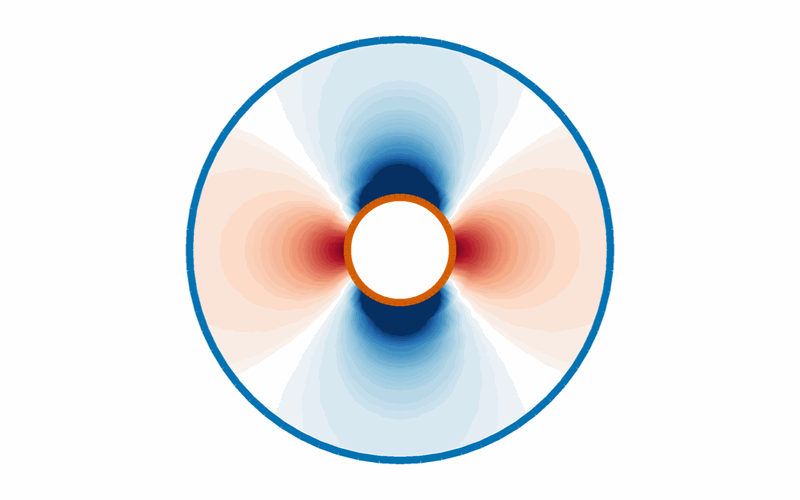

In [1]:
from IPython.display import Image

Image(filename="../../../docs/img/mesh/thumbnails/domain_mesh.png", width=480)

In [2]:
import tempfile

import matplotlib.pyplot as plt
import pyvista as pv
import torch

from physicsnemo.mesh import DomainMesh, Mesh
from physicsnemo.mesh.io import from_pyvista
from physicsnemo.mesh.projections import project
from physicsnemo.mesh.sampling import match_points
from physicsnemo.nn.functional.neighbors import knn

# Hide the hairline seams that antialiasing draws between filled triangles.
plt.rcParams["patch.antialiased"] = False

## 1. What a Domain Holds

A `DomainMesh` has three fields. The figure shows them for a simple case,
potential flow around a cylinder:

- `interior`: the `Mesh` where the solver computes the fields, here a
  `Mesh[2, 2]`. In 3D, a tetrahedral volume or a point cloud.
- `boundaries`: one named `Mesh` for each boundary condition, here curves
  (`Mesh[1, 2]`). In 3D, surfaces. Each boundary carries its own fields.
- `global_data`: domain-level quantities, such as a Reynolds number or the
  freestream velocity.

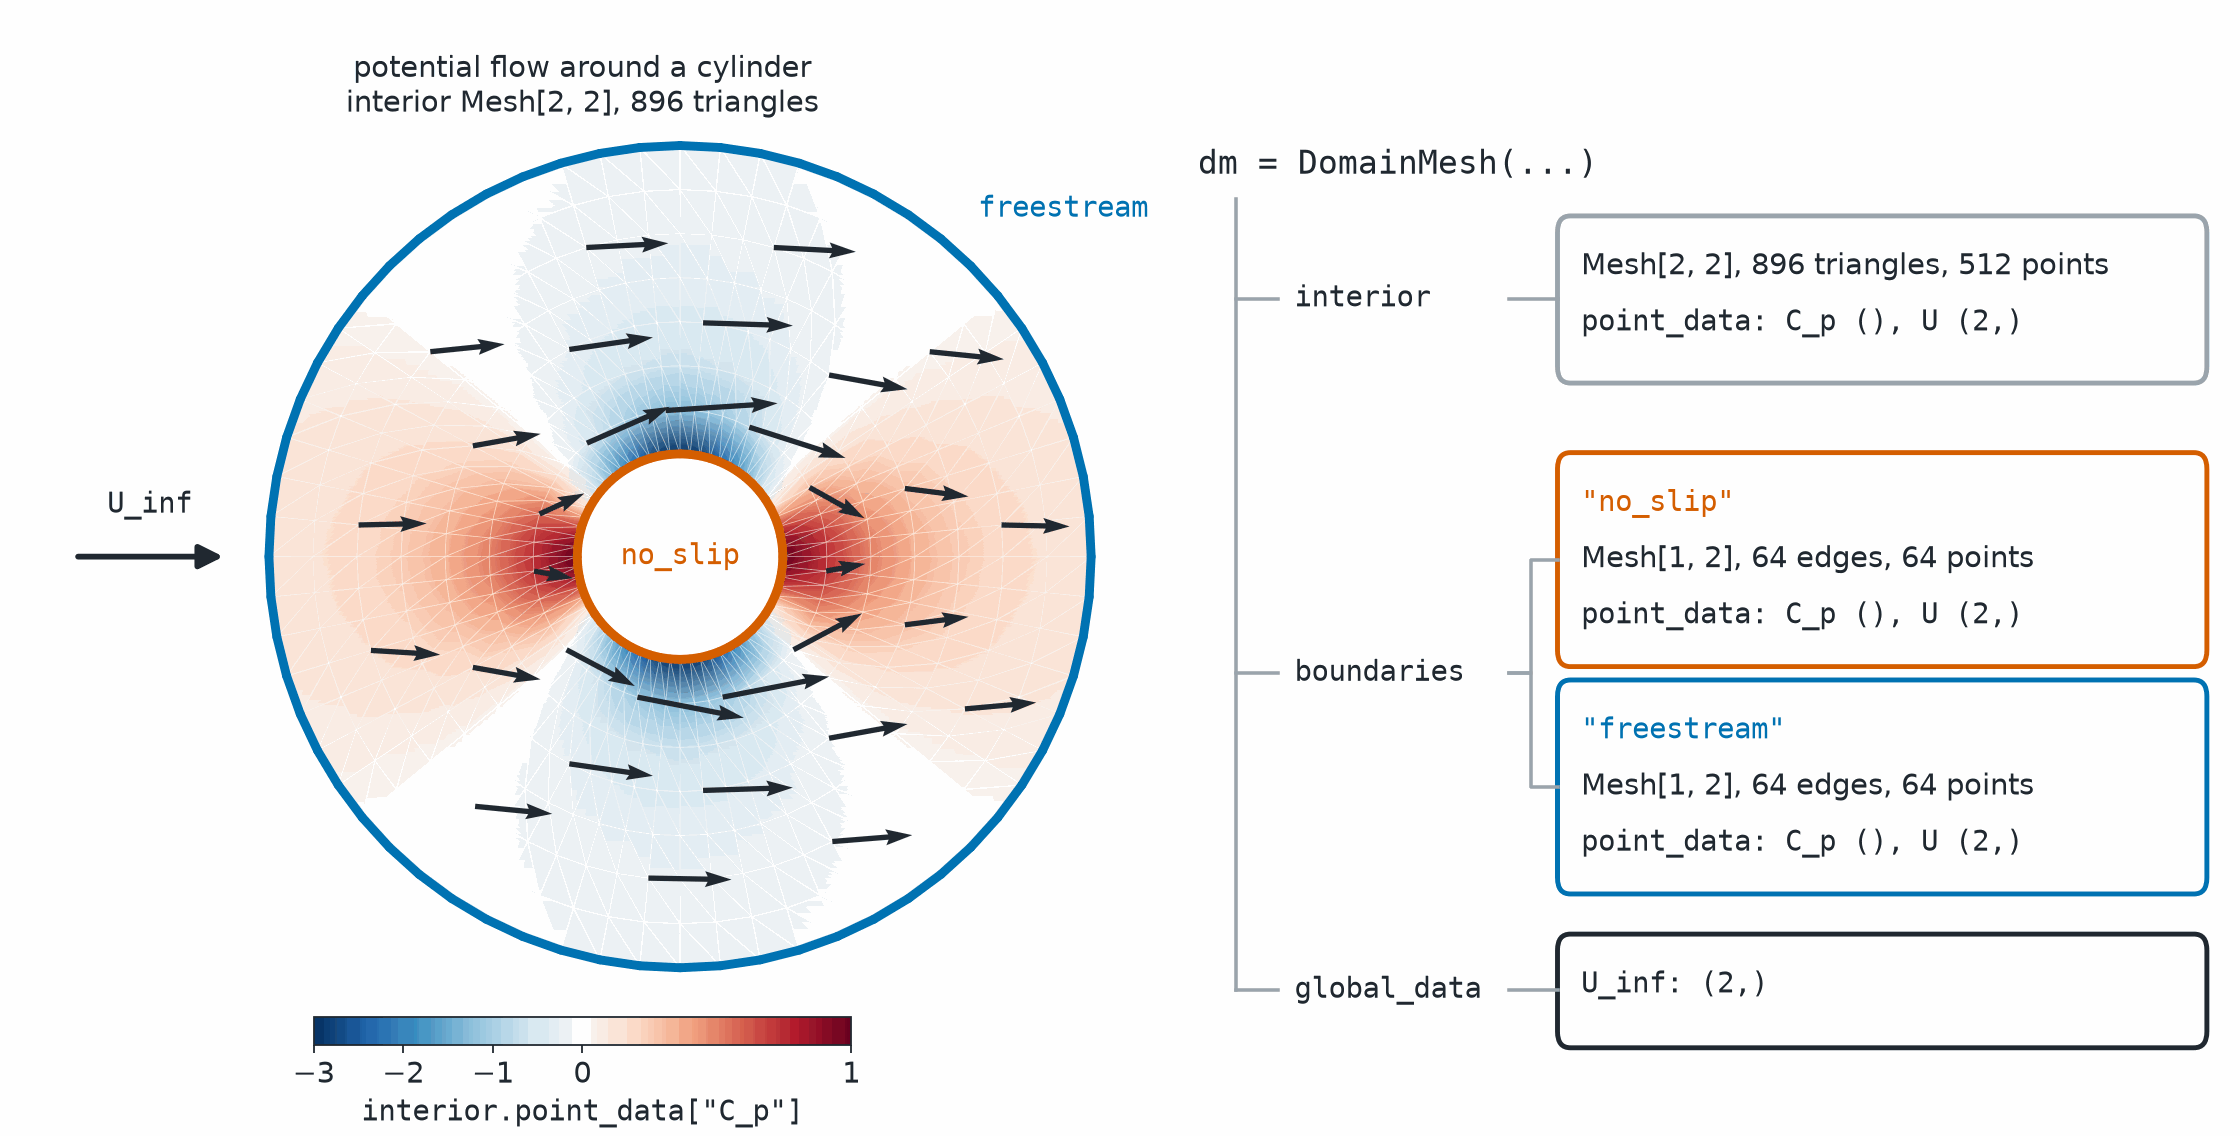

In [3]:
Image(filename="../../../docs/img/mesh/domain_mesh_anatomy.png", width=900)

The contract of a domain is that its merged boundaries enclose the interior.
The constructor does not check this, and `is_boundary_watertight()` checks one part of it (Section 4).
The PhysicsNeMo datapipes read samples as `DomainMesh` objects
(`physicsnemo.datapipes.readers.DomainMeshReader`), and their mesh transforms
act on whole domains.

## 2. Load a CFD Result

PyVista provides a small public CFD result: 2D flow past a cylinder at a
Reynolds number of 35 ([dataset page](https://docs.pyvista.org/api/examples/_autosummary/pyvista.examples.downloads.download_cylinder_crossflow.html)).
It is a `MultiBlock` with one block for each region:

| Block | Contents | Becomes |
|-------|----------|---------|
| `fluid` | Interior flow field | `interior`, a `Mesh[2, 2]` |
| `wall_cylinder` | Cylinder wall (no-slip) | `boundaries["cylinder"]`, a `Mesh[1, 2]` |
| `inlet`, `outlet`, `outlet_top`, `outlet_bottom` | Outer edges of the domain | `boundaries["freestream"]`, a `Mesh[1, 2]` |

In [4]:
case = pv.examples.download_cylinder_crossflow()
print(case.keys())

['fluid', 'inlet', 'outlet', 'outlet_top', 'outlet_bottom', 'wall_cylinder']


The file stores 2D data in 3D. Every point has `z = 0`, and velocities have a
zero third component. `project(keep_dims=[0, 1])` drops the z-axis. With
`transform_point_data=True`, it also drops the third component of vector
fields such as `velocity`. The helper below converts one block and keeps
only the three physical fields.

In [5]:
FIELDS = ("pressure", "velocity", "vorticity_mag")


def to_2d_mesh(block, manifold_dim="auto"):
    """Convert a PyVista block to a 2D Mesh with the physical fields."""
    mesh = project(
        from_pyvista(block, manifold_dim=manifold_dim),
        keep_dims=[0, 1],
        transform_point_data=True,
    )
    return Mesh(
        points=mesh.points,
        cells=mesh.cells,
        point_data=mesh.point_data.select(*FIELDS),
    )


interior = to_2d_mesh(case["fluid"])
print(interior)

Mesh[n_manifold_dims=2, n_spatial_dims=2](n_points=14831, n_cells=29149)
    point_data: {pressure: (), velocity: (2,), vorticity_mag: ()}


The boundary blocks hold line cells. Pass `manifold_dim=1` to keep them as
curves. The four outer patches share their corner points, so merge them into
one far-field boundary with `pv.merge`, which joins coincident points.

In [6]:
cylinder = to_2d_mesh(case["wall_cylinder"], manifold_dim=1)
farfield_block = pv.merge(
    [case[name] for name in ("inlet", "outlet", "outlet_top", "outlet_bottom")]
)
freestream = to_2d_mesh(farfield_block, manifold_dim=1)

print(f"cylinder:   {cylinder}")
print(f"freestream: {freestream}")

cylinder:   Mesh[n_manifold_dims=1, n_spatial_dims=2](n_points=63, n_cells=63)
    point_data: {pressure: (), velocity: (2,), vorticity_mag: ()}
freestream: Mesh[n_manifold_dims=1, n_spatial_dims=2](n_points=450, n_cells=450)
    point_data: {pressure: (), velocity: (2,), vorticity_mag: ()}


## 3. Assemble and Inspect the Domain

Each boundary keeps its own fields. Here, both boundaries carry the same three
fields, but in general they differ. For example, a wall can carry shear
stress, and an inlet a prescribed velocity. The freestream velocity `U_inf`
applies to the whole domain, so it goes in `global_data`. The inlet velocity
is uniform, so read it from the first inlet point.

In [7]:
U_inf = torch.from_numpy(case["inlet"].point_data["velocity"][0, :2])

dm = DomainMesh(
    interior=interior,
    boundaries={"cylinder": cylinder, "freestream": freestream},
    global_data={"U_inf": U_inf},
)
print(dm)

DomainMesh(
    interior: Mesh[n_manifold_dims=2, n_spatial_dims=2](n_points=14831, n_cells=29149)
        point_data: {pressure: (), velocity: (2,), vorticity_mag: ()}
    boundaries:
        cylinder  : Mesh[n_manifold_dims=1, n_spatial_dims=2](n_points=63, n_cells=63)
            point_data: {pressure: (), velocity: (2,), vorticity_mag: ()}
        freestream: Mesh[n_manifold_dims=1, n_spatial_dims=2](n_points=450, n_cells=450)
            point_data: {pressure: (), velocity: (2,), vorticity_mag: ()}
    global_data: {U_inf: (2,)}
)


Index boundaries by name, and read `global_data` like any `TensorDict`. The
dataset stores no units, so values are in its native units.

In [8]:
print(f"boundary names: {dm.boundary_names}")
print(f"cylinder points: {dm.boundaries['cylinder'].n_points}")
print(f"U_inf = {dm.global_data['U_inf'].tolist()}")

boundary names: ['cylinder', 'freestream']
cylinder points: 63
U_inf = [35.0, 0.0]


Iterating over a domain yields `(name, mesh)` pairs: the interior first, then
the boundaries in sorted order. This is the usual way to apply a check or a
feature computation to every part.

In [9]:
for name, mesh in dm:
    print(
        f"{name:10s} manifold dims={mesh.n_manifold_dims}  points={mesh.n_points:6d}  cells={mesh.n_cells:6d}"
    )

interior   manifold dims=2  points= 14831  cells= 29149
cylinder   manifold dims=1  points=    63  cells=    63
freestream manifold dims=1  points=   450  cells=   450


## 4. Check the Domain

`validate()` runs `Mesh.validate()` on every part and combines the reports.
The domain is valid only if every part is.

In [10]:
report = dm.validate()
print(f"domain valid: {report['valid']}")
print(f"  interior:   {report['interior']['valid']}")
for name, boundary_report in report["boundaries"].items():
    print(f"  {name:10s}: {boundary_report['valid']}")

domain valid: True
  interior:   True
  cylinder  : True
  freestream: True


`is_boundary_watertight()` checks one part of the contract from Section 1. It
merges all boundaries, joins points closer than `tolerance` (default `1e-6`), and calls
`is_watertight()` on the result. In 2D, the merged boundary is watertight when
every point lies on exactly two segments. In that case, each boundary is a
closed curve. The check does not compare the positions of the boundaries with
the interior: a closed boundary moved away from the interior still passes.

In [11]:
print(f"boundaries enclose the interior: {dm.is_boundary_watertight()}")

boundaries enclose the interior: True


## 5. Draw the Domain

`DomainMesh.draw()` colors the interior by a field and draws the boundary
curves over it. `boundary_kwargs` sets how the boundaries look. Here,
`show_edges=True` draws them as black lines. To zoom in on the cylinder, pass
your own `Axes` with `ax=`, then set its limits.

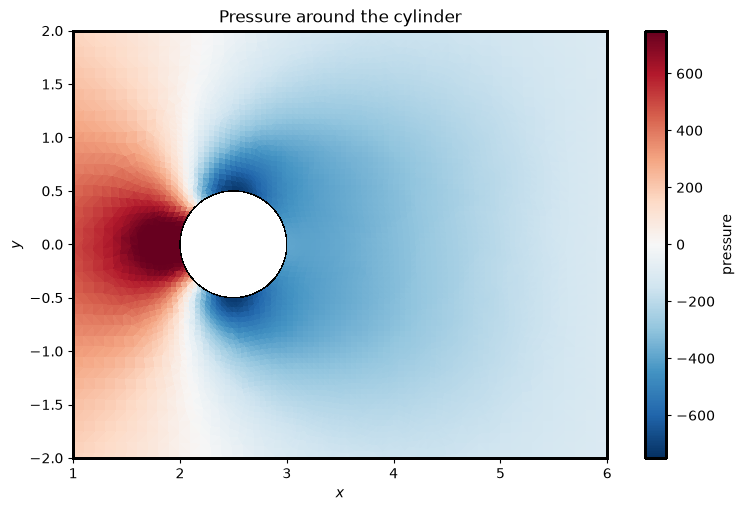

In [12]:
pressure_limit = 750.0  # symmetric color range, in native units

fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
dm.draw(
    point_scalars="pressure",
    cmap="RdBu_r",
    vmin=-pressure_limit,
    vmax=pressure_limit,
    backend="matplotlib",
    boundary_kwargs={"show_edges": True},
    ax=ax,
    show=False,
)
ax.set(
    xlim=(1, 6),
    ylim=(-2, 2),
    xlabel="$x$",
    ylabel="$y$",
    title="Pressure around the cylinder",
)
plt.show()

The flow comes from the left. Pressure is highest at the front stagnation
point of the cylinder, and lowest on its upper and lower sides.

## 6. Rotate a Domain for Data Augmentation

A model that is not rotation-equivariant can learn to handle different
orientations from rotated copies of each sample. A rotated copy must rotate
the geometry, the boundaries, and every vector field together, while scalars
such as pressure stay unchanged.

`DomainMesh.rotate()` rotates the interior and every boundary. You name the
vector fields: `transform_point_data={"velocity": True}` rotates `velocity` on
each mesh, and `transform_global_data={"U_inf": True}` rotates the freestream
vector. Passing `True` rotates every vector and tensor field, and raises a
`ValueError` for a field of any other shape. Name the fields explicitly when
a field with a vector shape is not a vector, such as two unrelated channels.
In [Tutorial 9](tutorial_9_ml_integration.ipynb), `FieldSchema` makes these
declarations part of a model. A rotation keeps lengths, so speed and pressure
do not change.

In [13]:
angle = 0.5  # radians
dm_rotated = dm.rotate(
    angle=angle,
    transform_point_data={"velocity": True},
    transform_global_data={"U_inf": True},
)

print(f"U_inf before: {dm.global_data['U_inf'].tolist()}")
print(
    f"U_inf after:  {[round(v, 3) for v in dm_rotated.global_data['U_inf'].tolist()]}"
)

speed_before = dm.interior.point_data["velocity"].norm(dim=-1)
speed_after = dm_rotated.interior.point_data["velocity"].norm(dim=-1)
print(f"max speed change:    {(speed_after - speed_before).abs().max():.2e}")
print(
    f"max pressure change: {(dm_rotated.interior.point_data['pressure'] - dm.interior.point_data['pressure']).abs().max():.2e}"
)

U_inf before: [35.0, 0.0]
U_inf after:  [30.715, 16.78]
max speed change:    7.63e-06
max pressure change: 0.00e+00


Draw both domains on the same pressure scale. The rotation turns about the
origin, which is at the inlet, so the cylinder also moves. Each panel is
centered on its own cylinder, and the field turns with the geometry.

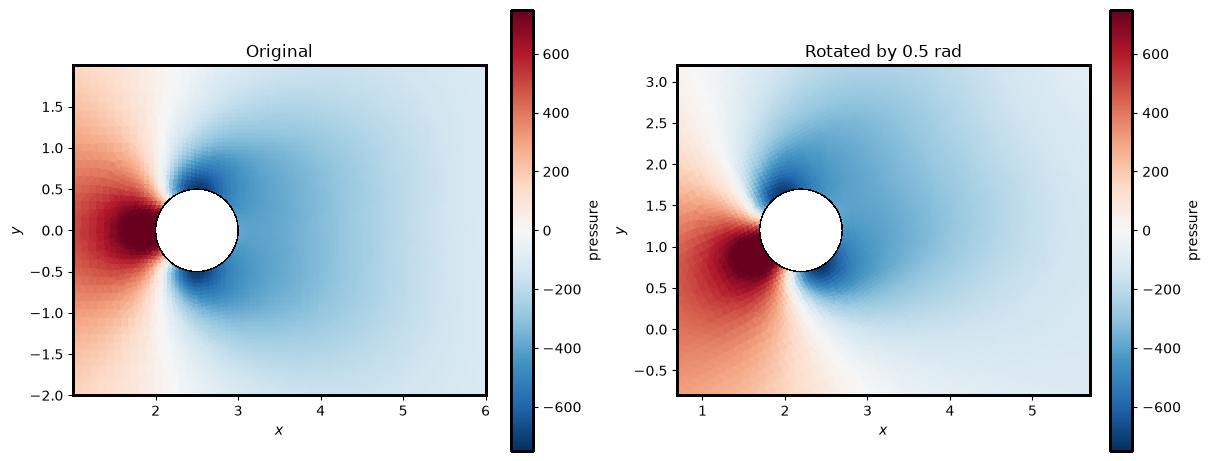

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
for ax, domain, title in zip(
    axes, (dm, dm_rotated), ("Original", f"Rotated by {angle} rad"), strict=True
):
    domain.draw(
        point_scalars="pressure",
        cmap="RdBu_r",
        vmin=-pressure_limit,
        vmax=pressure_limit,
        backend="matplotlib",
        boundary_kwargs={"show_edges": True},
        ax=ax,
        show=False,
    )
    cx, cy = domain.boundaries["cylinder"].points.mean(dim=0).tolist()
    ax.set(
        xlim=(cx - 1.5, cx + 3.5),
        ylim=(cy - 2, cy + 2),
        xlabel="$x$",
        ylabel="$y$",
        title=title,
    )
plt.show()

Pass `center=` to rotate about another point. Transforms chain, because each
call returns a new `DomainMesh`.

In [15]:
dm_transformed = dm.translate([1.0, 0.0]).rotate(angle=0.2).scale(2.0)
for name, mesh in dm_transformed:
    centroid = mesh.points.mean(dim=0)
    print(f"{name:10s} centroid = [{centroid[0]:.2f}, {centroid[1]:.2f}]")

interior   centroid = [14.92, 3.02]
cylinder   centroid = [6.86, 1.39]
freestream centroid = [16.66, 3.38]


For any other `Mesh -> Mesh` function, use `apply_to_meshes()`. The built-in
transforms use it too. Here, it refines every part with one level of linear
subdivision.

In [16]:
dm_fine = dm.apply_to_meshes(lambda m: m.subdivide(levels=1))
for (name, mesh), (_, fine) in zip(dm, dm_fine, strict=True):
    print(f"{name:10s} cells: {mesh.n_cells:6d} -> {fine.n_cells:6d}")

interior   cells:  29149 -> 116596
cylinder   cells:     63 ->    126
freestream cells:    450 ->    900


The PhysicsNeMo datapipes provide random versions of these transforms for
training, such as `RandomRotateMesh` in `physicsnemo.datapipes.transforms.mesh`.

## 7. Spatial Queries across Meshes

Many features combine two parts of a domain. The distance from each interior
point to the nearest wall is a common input feature for flow models. A k-nearest
neighbor search (`knn`) of the interior points against the cylinder points
gives it.

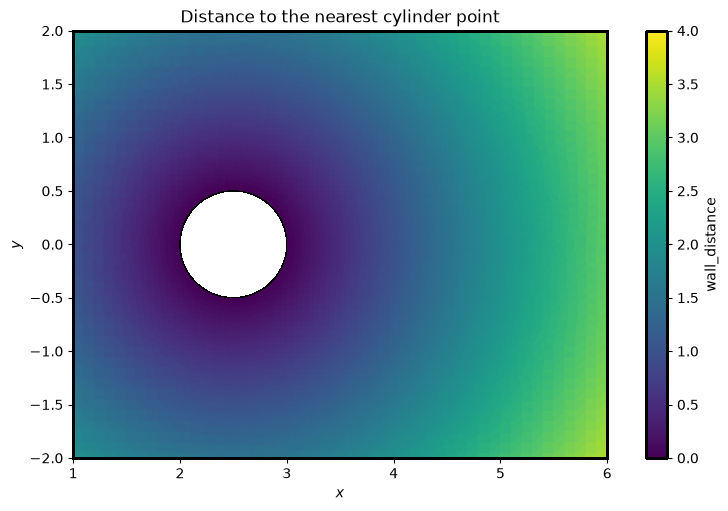

In [17]:
_, distance = knn(
    points=dm.boundaries["cylinder"].points, queries=dm.interior.points, k=1
)
dm.interior.point_data["wall_distance"] = distance[:, 0]

fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
dm.draw(
    point_scalars="wall_distance",
    cmap="viridis",
    vmin=0,
    vmax=4,
    backend="matplotlib",
    boundary_kwargs={"show_edges": True},
    ax=ax,
    show=False,
)
ax.set(
    xlim=(1, 6),
    ylim=(-2, 2),
    xlabel="$x$",
    ylabel="$y$",
    title="Distance to the nearest cylinder point",
)
plt.show()

This is the distance to the nearest cylinder vertex, not to the nearest point
on the cylinder's edges. Its error is at most about one boundary edge
length. For a 3D triangle surface, `signed_distance_field` in
`physicsnemo.mesh.spatial` gives the distance to the nearest point on the
surface. Refer to the
[spatial API reference](https://docs.nvidia.com/physicsnemo/latest/physicsnemo/api/mesh/spatial.html).

`match_points(source, target, tolerance)` finds, for each source point, the
nearest target point within `tolerance`. Here, it shows that every cylinder
point is also an interior point, so you can copy wall values onto the
interior by index.

In [18]:
cylinder_index, interior_index = match_points(
    dm.boundaries["cylinder"].points, dm.interior.points, tolerance=1e-6
)
print(
    f"cylinder points matched to interior points: {len(cylinder_index)} of {dm.boundaries['cylinder'].n_points}"
)

cylinder points matched to interior points: 63 of 63


## 8. Save and Load a Domain

`save()` writes every tensor of the domain to a directory as memory-mapped
files. `DomainMesh.load()` reads it back. Unlike `torch.save`, this format runs
no pickled code when it loads, and it can read tensors lazily.

In [19]:
with tempfile.TemporaryDirectory() as directory:
    dm.save(directory)
    reloaded = DomainMesh.load(directory)
    print(reloaded.boundary_names)
    print(torch.equal(reloaded.interior.points, dm.interior.points))

['cylinder', 'freestream']
True


## Summary

This tutorial covered the following points:

- `DomainMesh` holds an `interior` mesh, named `boundaries`, and domain-level
  `global_data`. Iterating over it yields `(name, mesh)` pairs, the interior
  first.
- `validate()` combines the reports of every part, and
  `is_boundary_watertight()` checks that the merged boundaries are closed.
- `translate()`, `rotate()`, `scale()`, `transform()`, and
  `apply_to_meshes(fn)` act on every part. `transform_point_data` and
  `transform_global_data` name the vector fields that rotate with the
  geometry.
- `save()` and `DomainMesh.load()` store a domain as memory-mapped tensors.

## Next Steps

Continue with the following resources:

- API Reference:
  [core (`Mesh` and `DomainMesh`)](https://docs.nvidia.com/physicsnemo/latest/physicsnemo/api/mesh/core.html)
  and [sampling](https://docs.nvidia.com/physicsnemo/latest/physicsnemo/api/mesh/sampling.html).
- User Guide:
  [Simulation Domains with DomainMesh](https://docs.nvidia.com/physicsnemo/latest/user-guide/mesh/domain_mesh.html).

**Next:** [Tutorial 9: Meshes in ML Pipelines](tutorial_9_ml_integration.ipynb)
turns meshes into model inputs and trains a graph model on the edge graph of
a surface.